# 01 — EDA, Nettoyage et Tests statistiques
**Projet Data Mining — Satisfaction des passagers aériens** (Parcours A : classification supervisée)

**Dataset** : Airline Passenger Satisfaction (Kaggle, `mysarahmadbhat`) — ~129 880 observations, 24 variables.
**Cible** : `Satisfaction` (Satisfied = 1 / Neutral or Dissatisfied = 0)

**Plan**
1. Chargement et structure
2. Typage des variables
3. Valeurs manquantes et doublons
4. Statistiques descriptives
5. Analyse de la cible
6. Distributions (histogrammes + KDE) et outliers (règle de Tukey)
7. Fréquences catégorielles
8. Corrélations (Pearson / Spearman)
9. Tests statistiques (justifiés, correction Benjamini-Hochberg)
10. Nettoyage et sauvegarde

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42
ALPHA = 0.05

RAW_PATH = Path("../data/raw/airline_passenger_satisfaction.csv")
PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

## 1. Chargement et structure

In [2]:
df = pd.read_csv(RAW_PATH)
df.columns = df.columns.str.strip()          # enlève les espaces parasites dans les noms
print("Dimensions brutes :", df.shape)
df.head()

Dimensions brutes : (129880, 24)


,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,Check-in Service,Online Boarding,Gate Location,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,3,4,3,3,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,2,3,5,2,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,4,4,5,4,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,2,3,4,2,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,3,3,5,3,3,4,4,5,4,3,3,3,3,Satisfied


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 24 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   ID                                      129880 non-null  int64  
 1   Gender                                  129880 non-null  str    
 2   Age                                     129880 non-null  int64  
 3   Customer Type                           129880 non-null  str    
 4   Type of Travel                          129880 non-null  str    
 5   Class                                   129880 non-null  str    
 6   Flight Distance                         129880 non-null  int64  
 7   Departure Delay                         129880 non-null  int64  
 8   Arrival Delay                           129487 non-null  float64
 9   Departure and Arrival Time Convenience  129880 non-null  int64  
 10  Ease of Online Booking                  129880 non-null

## 2. Typage des variables
On repère automatiquement : l'identifiant, la cible, les notes de service (ordinales 0–5),
les autres variables quantitatives et les variables catégorielles.
> ⚠️ Vérifier que la liste obtenue correspond à `data_dictionary.csv`.

In [4]:
# Identifiant(s) à retirer (non informatifs)
ID_COLS = [c for c in df.columns if c.lower() in ("id", "unnamed: 0")]

# Cible
TARGET = next(c for c in df.columns if c.lower() == "satisfaction")

num_all = df.select_dtypes(include="number").columns.difference(ID_COLS)
# Notes de service : entiers dont les valeurs sont dans {0..5}
RATING_COLS = [c for c in num_all
               if df[c].dropna().nunique() <= 6 and df[c].dropna().between(0, 5).all()]
NUM_COLS = [c for c in num_all if c not in RATING_COLS]
CAT_COLS = [c for c in df.select_dtypes(exclude="number").columns if c != TARGET]

typage = pd.DataFrame({
    "Colonne": ID_COLS + [TARGET] + NUM_COLS + RATING_COLS + CAT_COLS,
    "Type": (["identifiant"] * len(ID_COLS) + ["cible"] + ["quantitative"] * len(NUM_COLS)
             + ["ordinale (0-5)"] * len(RATING_COLS) + ["catégorielle"] * len(CAT_COLS)),
})
print(f"{len(NUM_COLS)} quantitatives | {len(RATING_COLS)} ordinales | {len(CAT_COLS)} catégorielles")
typage

4 quantitatives | 14 ordinales | 4 catégorielles


,Colonne,Type
0,ID,identifiant
1,Satisfaction,cible
2,Age,quantitative
3,Arrival Delay,quantitative
4,Departure Delay,quantitative
5,Flight Distance,quantitative
6,Baggage Handling,ordinale (0-5)
7,Check-in Service,ordinale (0-5)
8,Cleanliness,ordinale (0-5)
9,Departure and Arrival Time Convenience,ordinale (0-5)


## 3. Valeurs manquantes et doublons

In [5]:
na = pd.DataFrame({"manquants": df.isna().sum(), "taux_%": (df.isna().mean() * 100).round(3)})
na = na[na["manquants"] > 0].sort_values("manquants", ascending=False)
print(na if len(na) else "Aucune valeur manquante")

# Chaînes vides / espaces (invisibles pour isna)
empty_str = {c: int((df[c].astype(str).str.strip() == "").sum()) for c in CAT_COLS + [TARGET]}
print("Chaînes vides :", {k: v for k, v in empty_str.items() if v})

# Doublons (en ignorant l'identifiant, qui est unique par construction)
n_dup = df.drop(columns=ID_COLS).duplicated().sum()
print("Doublons (hors ID) :", n_dup)

               manquants  taux_%
Arrival Delay        393   0.303
Chaînes vides : {}
Doublons (hors ID) : 0


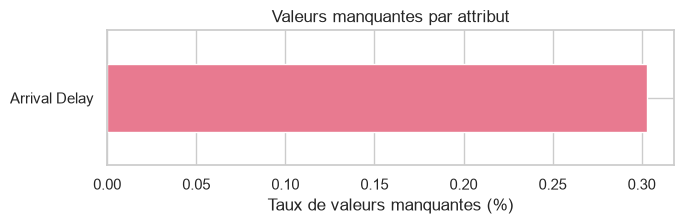

In [6]:
if len(na):
    ax = na["taux_%"].plot.barh(color="#e87a90", figsize=(7, 2 + 0.4 * len(na)))
    ax.set_xlabel("Taux de valeurs manquantes (%)"); ax.set_title("Valeurs manquantes par attribut")
    plt.tight_layout(); plt.show()

## 4. Statistiques descriptives

In [7]:
desc = df[NUM_COLS + RATING_COLS].describe().T
desc["médiane"] = df[NUM_COLS + RATING_COLS].median()
desc["asymétrie (skew)"] = df[NUM_COLS + RATING_COLS].skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,médiane,asymétrie (skew)
Age,129880.0,39.43,15.12,7.0,27.0,40.0,51.0,85.0,40.0,-0.00
Arrival Delay,129487.0,15.09,38.47,0.0,0.0,0.0,13.0,1584.0,0.0,6.67
Departure Delay,129880.0,14.71,38.07,0.0,0.0,0.0,12.0,1592.0,0.0,6.82
Flight Distance,129880.0,1190.32,997.45,31.0,414.0,844.0,1744.0,4983.0,844.0,1.11
Baggage Handling,129880.0,3.63,1.18,1.0,3.0,4.0,5.0,5.0,4.0,-0.68
Check-in Service,129880.0,3.31,1.27,0.0,3.0,3.0,4.0,5.0,3.0,-0.37
Cleanliness,129880.0,3.29,1.31,0.0,2.0,3.0,4.0,5.0,3.0,-0.30
Departure and Arrival Time Convenience,129880.0,3.06,1.53,0.0,2.0,3.0,4.0,5.0,3.0,-0.33
Ease of Online Booking,129880.0,2.76,1.40,0.0,2.0,3.0,4.0,5.0,3.0,-0.02
Food and Drink,129880.0,3.20,1.33,0.0,2.0,3.0,4.0,5.0,3.0,-0.16


In [8]:
# Notes à 0 : à interpréter via data_dictionary.csv (souvent « non applicable »)
zeros = (df[RATING_COLS] == 0).sum().rename("nb_zeros").to_frame()
zeros["taux_%"] = (zeros["nb_zeros"] / len(df) * 100).round(2)
zeros.sort_values("nb_zeros", ascending=False)

,nb_zeros,taux_%
Departure and Arrival Time Convenience,6681,5.14
Ease of Online Booking,5682,4.37
In-flight Wifi Service,3916,3.02
Online Boarding,3080,2.37
Leg Room Service,598,0.46
Food and Drink,132,0.10
In-flight Entertainment,18,0.01
Cleanliness,14,0.01
On-board Service,5,0.00
In-flight Service,5,0.00


## 5. Analyse de la variable cible

                         effectif      %
Satisfaction                            
Neutral or Dissatisfied     73452  56.55
Satisfied                   56428  43.45


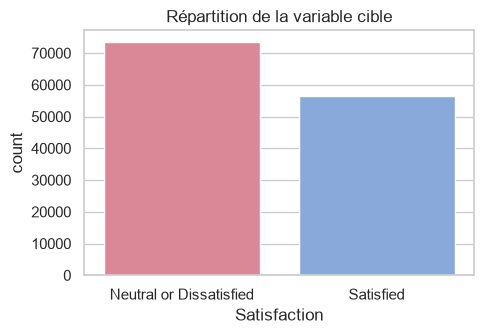

In [9]:
vc = df[TARGET].value_counts()
vp = df[TARGET].value_counts(normalize=True).mul(100).round(2)
print(pd.DataFrame({"effectif": vc, "%": vp}))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x=TARGET, palette=["#e87a90", "#7aa6e8"], ax=ax)
ax.set_title("Répartition de la variable cible"); plt.tight_layout(); plt.show()

In [10]:
# Taux de la classe majoritaire = accuracy du classifieur Zero-R (baseline)
print(f"Baseline Zero-R attendue : {vp.max():.2f} % d'accuracy")

Baseline Zero-R attendue : 56.55 % d'accuracy


## 6. Distributions (histogrammes + KDE) et outliers (règle de Tukey / IQR)

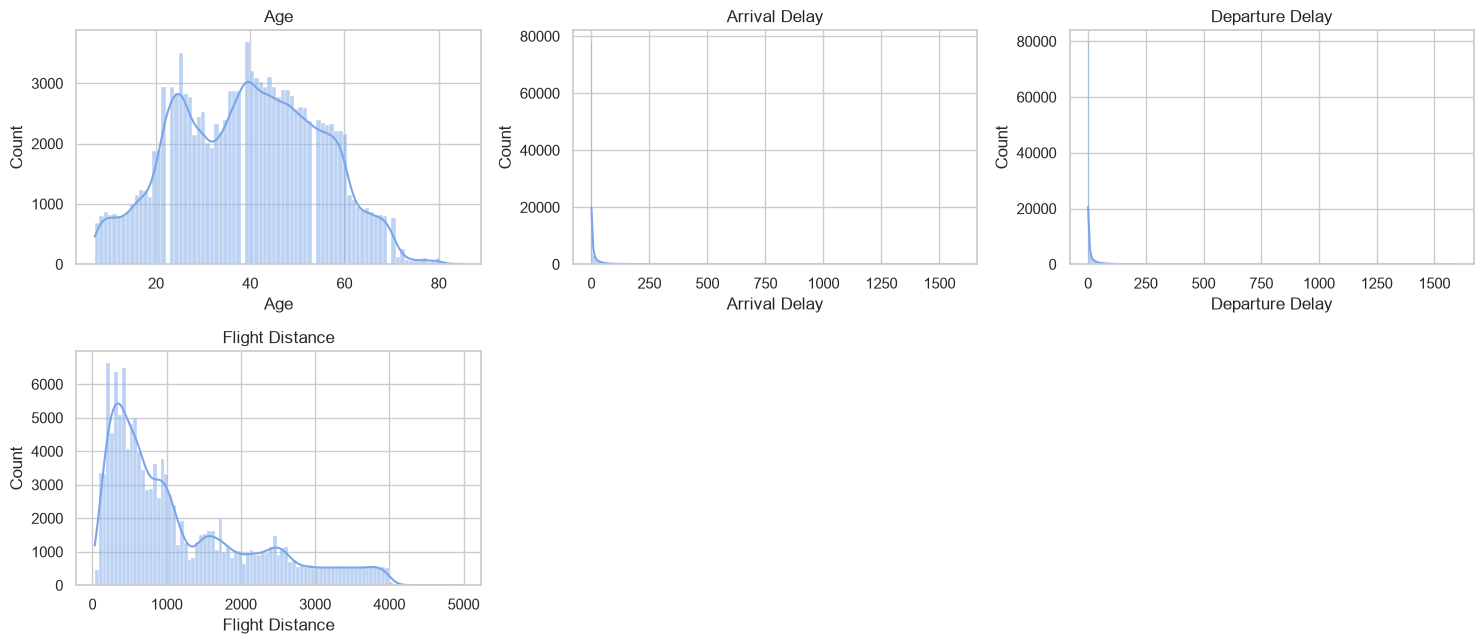

In [11]:
def plot_dist(cols, ncols=3):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.3 * nrows))
    for ax, c in zip(np.array(axes).ravel(), cols):
        sns.histplot(df[c].dropna(), kde=True, ax=ax, color="#7aa6e8")
        ax.set_title(c)
    for ax in np.array(axes).ravel()[len(cols):]:
        ax.axis("off")
    plt.tight_layout(); plt.show()

plot_dist(NUM_COLS)

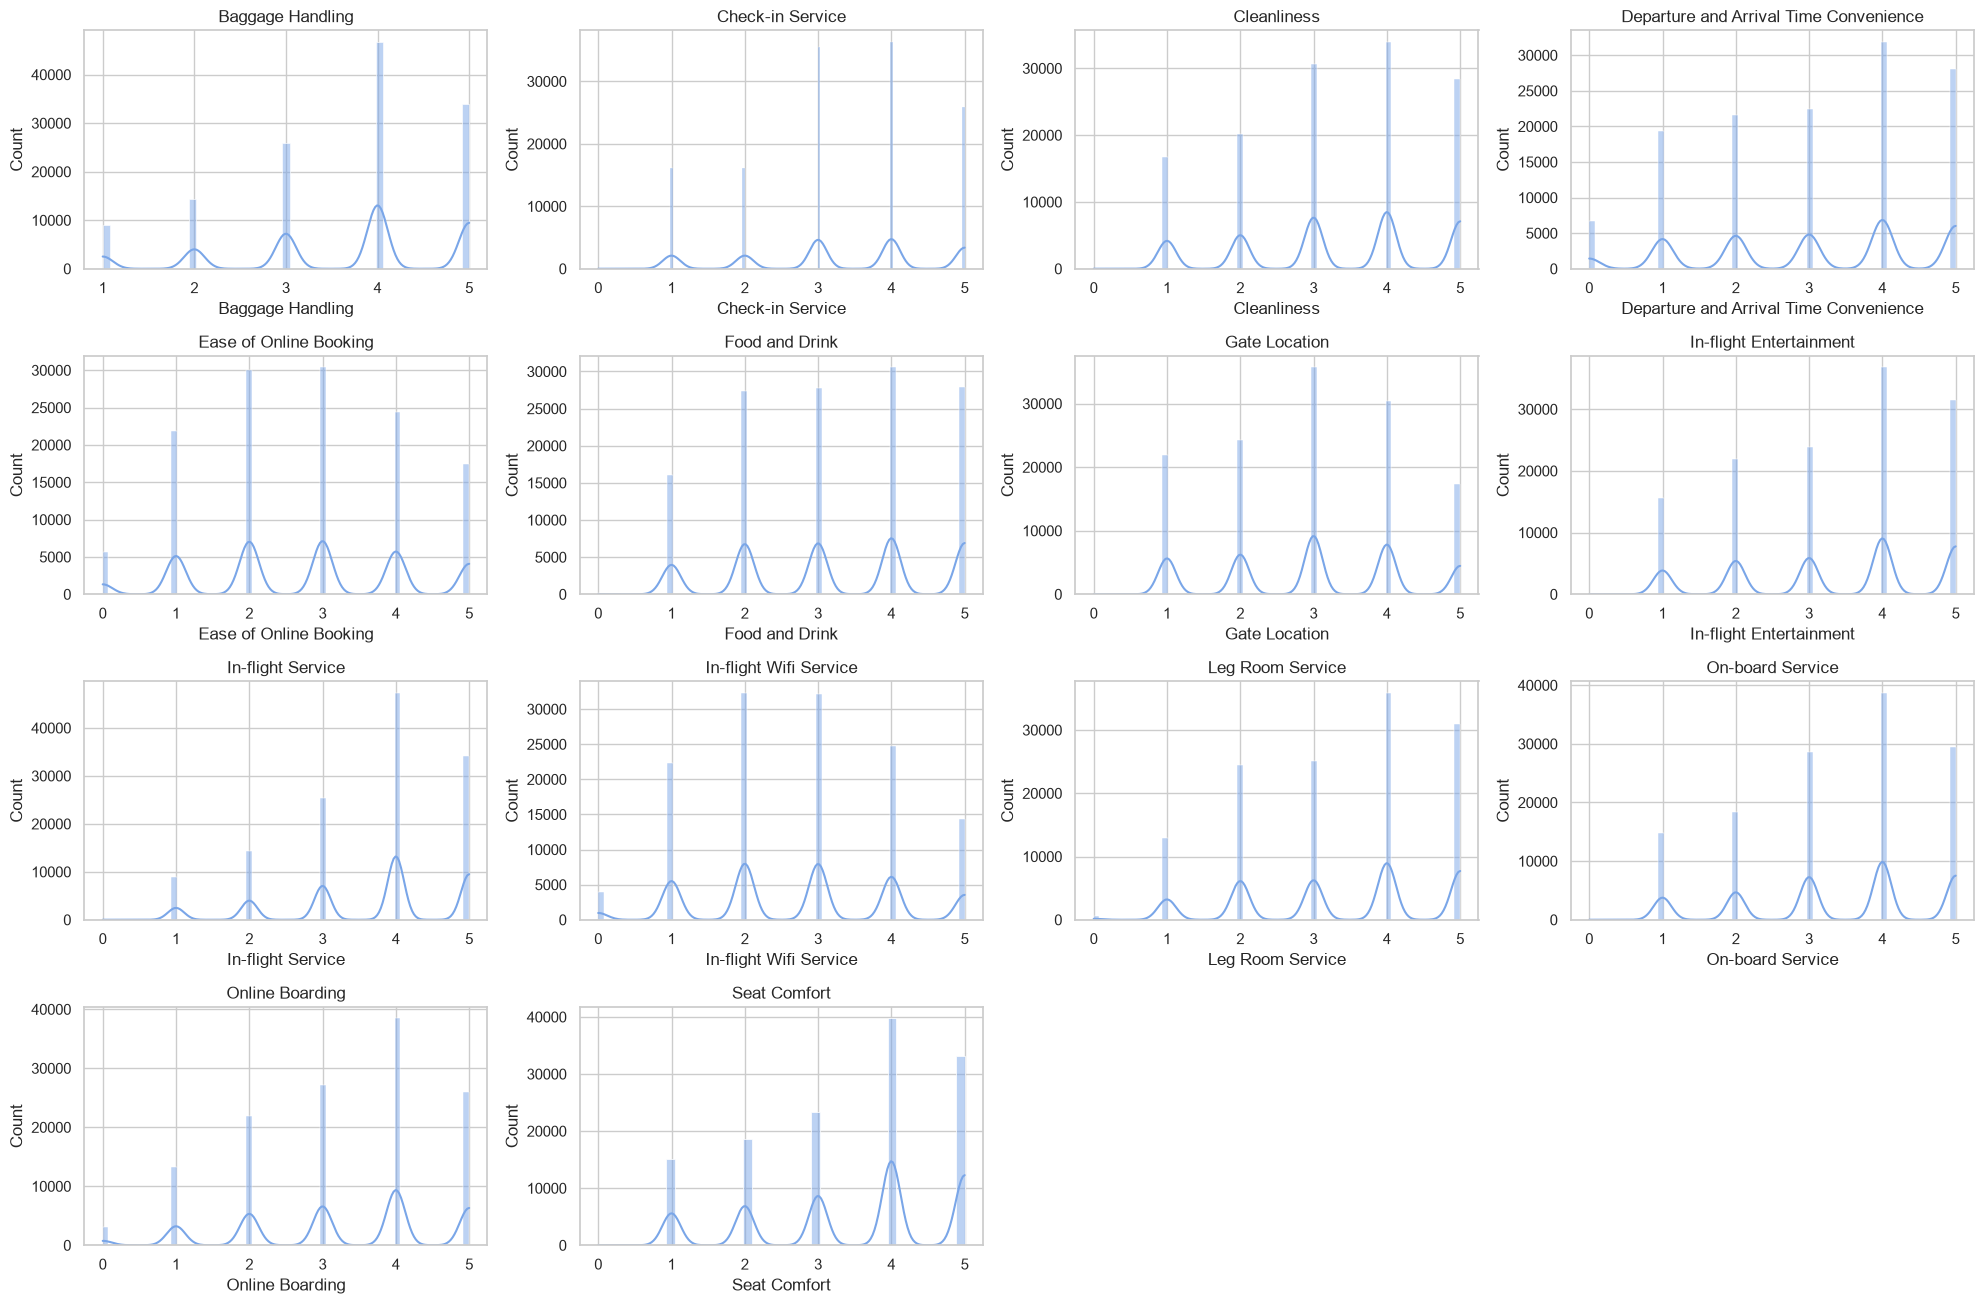

In [12]:
plot_dist(RATING_COLS, ncols=4)

In [13]:
# Outliers : règle de Tukey (< Q1 - 1.5·IQR ou > Q3 + 1.5·IQR)
rows = []
for c in NUM_COLS:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[c] < lo) | (df[c] > hi)).sum())
    rows.append([c, round(lo, 1), round(hi, 1), n_out, round(n_out / df[c].notna().sum() * 100, 2)])
outliers = pd.DataFrame(rows, columns=["variable", "borne_basse", "borne_haute", "nb_outliers", "taux_%"])
outliers

,variable,borne_basse,borne_haute,nb_outliers,taux_%
0,Age,-9.0,87.0,0,0.00
1,Arrival Delay,-19.5,32.5,17492,13.51
2,Departure Delay,-18.0,30.0,18098,13.93
3,Flight Distance,-1581.0,3739.0,2855,2.20


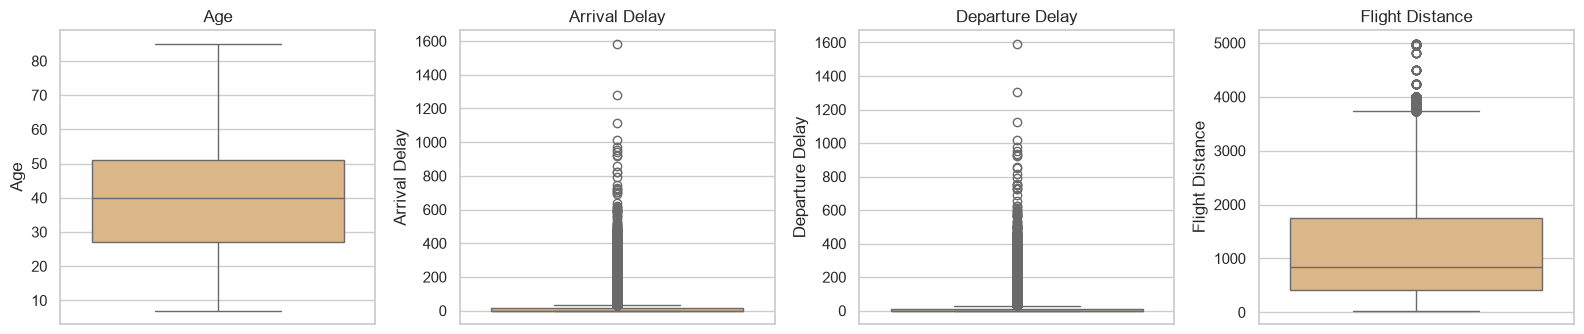

In [14]:
fig, axes = plt.subplots(1, len(NUM_COLS), figsize=(4 * len(NUM_COLS), 3.5))
for ax, c in zip(np.atleast_1d(axes), NUM_COLS):
    sns.boxplot(y=df[c], ax=ax, color="#e8b87a"); ax.set_title(c)
plt.tight_layout(); plt.show()

**Décision (à adapter selon vos résultats)** : les outliers de `Departure/Arrival Delay` et `Flight Distance`
correspondent à des situations réelles (gros retards, vols long-courriers). Ils sont **conservés** :
les modèles à base d'arbres y sont robustes et la standardisation limite leur effet pour K-NN/SVM.

## 7. Fréquences catégorielles

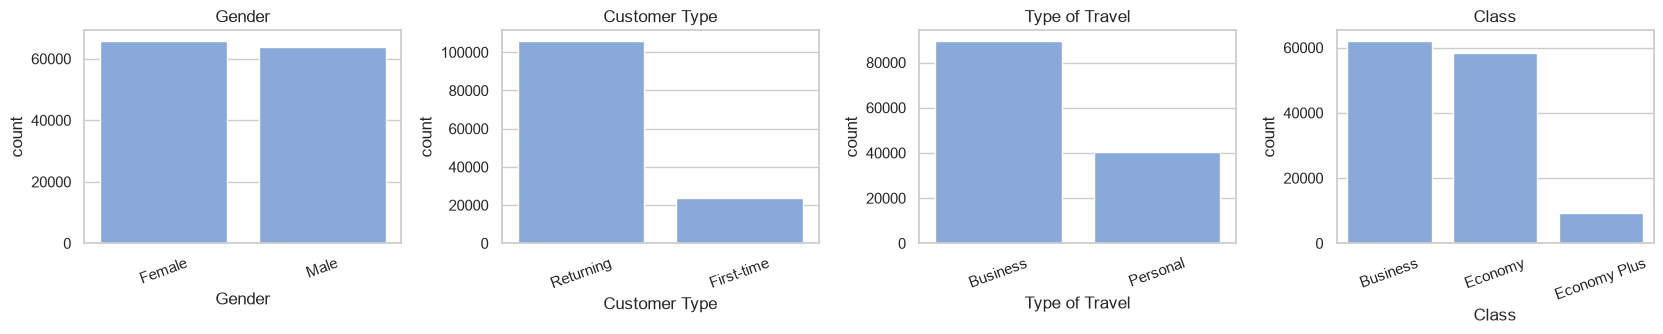

In [15]:
fig, axes = plt.subplots(1, len(CAT_COLS), figsize=(4.2 * len(CAT_COLS), 3.5))
for ax, c in zip(np.atleast_1d(axes), CAT_COLS):
    sns.countplot(data=df, x=c, order=df[c].value_counts().index, ax=ax, color="#7aa6e8")
    ax.set_title(c); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

In [16]:
# Taux de satisfaction par modalité (aperçu métier)
y_bin = (df[TARGET].str.strip().str.lower() == "satisfied").astype(int)
for c in CAT_COLS:
    print((y_bin.groupby(df[c]).mean() * 100).round(1).rename(f"% satisfaits | {c}").to_frame().T, "\n")

Gender                 Female  Male
% satisfaits | Gender    42.9  44.0 

Customer Type                 First-time  Returning
% satisfaits | Customer Type        24.0       47.8 

Type of Travel                 Business  Personal
% satisfaits | Type of Travel      58.4      10.1 

Class                 Business  Economy  Economy Plus
% satisfaits | Class      69.4     18.8          24.6 



## 8. Corrélations

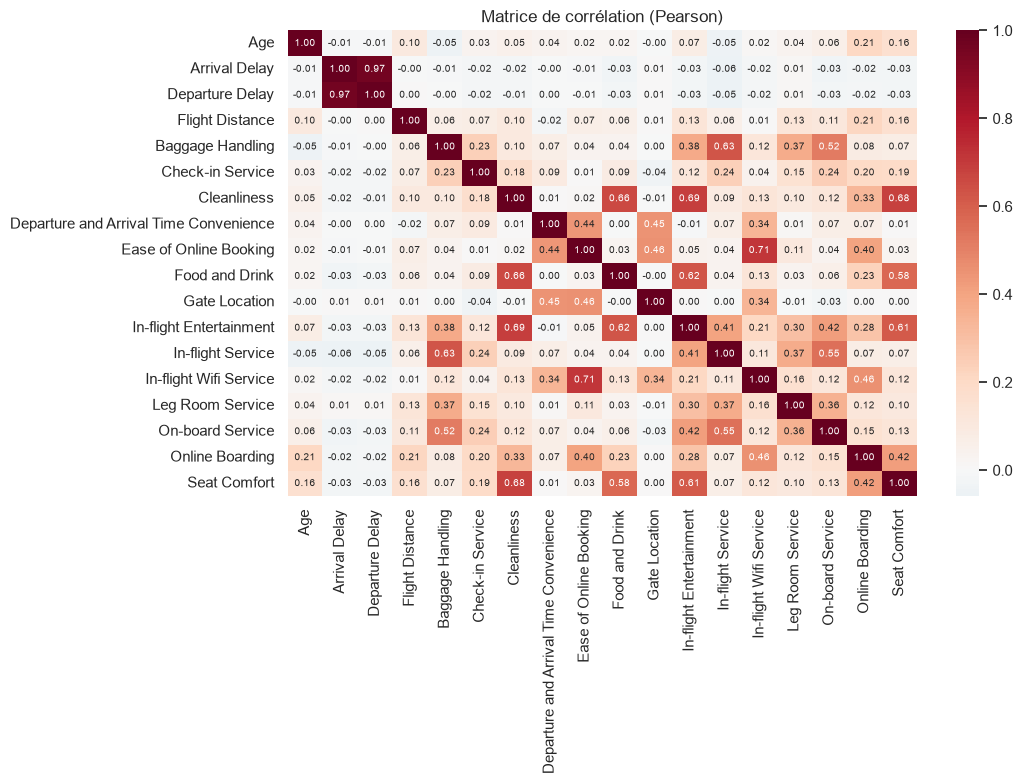

In [17]:
corr_cols = NUM_COLS + RATING_COLS
corr_p = df[corr_cols].corr(method="pearson")
plt.figure(figsize=(11, 8))
sns.heatmap(corr_p, annot=True, fmt=".2f", cmap="RdBu_r", center=0, annot_kws={"size": 7})
plt.title("Matrice de corrélation (Pearson)"); plt.tight_layout(); plt.show()

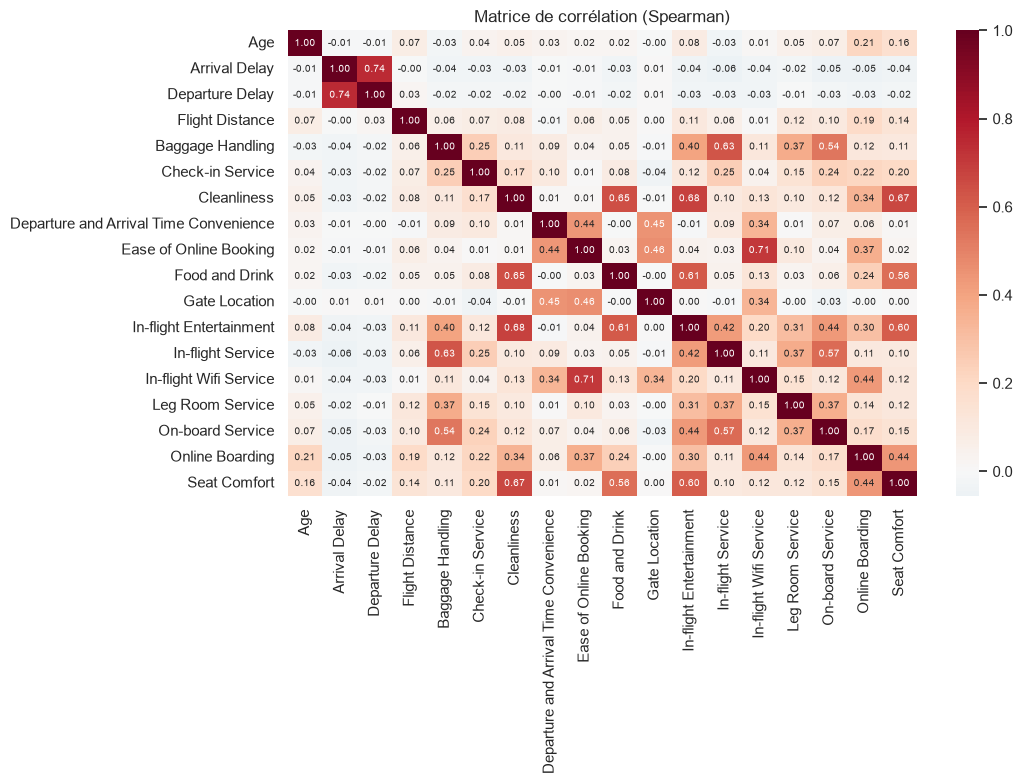

,Spearman vs cible
Online Boarding,0.550
In-flight Entertainment,0.400
Seat Comfort,0.362
On-board Service,0.328
Leg Room Service,0.317
Cleanliness,0.305
In-flight Wifi Service,0.287
Baggage Handling,0.271
In-flight Service,0.266
Flight Distance,0.257


In [18]:
# Spearman : plus adapté aux variables ordinales (notes 0-5) et aux distributions asymétriques
corr_s = df[corr_cols].corr(method="spearman")
plt.figure(figsize=(11, 8))
sns.heatmap(corr_s, annot=True, fmt=".2f", cmap="RdBu_r", center=0, annot_kws={"size": 7})
plt.title("Matrice de corrélation (Spearman)"); plt.tight_layout(); plt.show()

# Corrélation avec la cible (Spearman)
corr_target = df[corr_cols].apply(lambda s: s.corr(y_bin, method="spearman")).sort_values(ascending=False)
corr_target.round(3).to_frame("Spearman vs cible")

## 9. Tests statistiques (α = 0,05)

| # | Test | Variables | Justification du choix |
|---|------|-----------|------------------------|
| H1 | Mann-Whitney U | `Age` vs `Satisfaction` | Quantitative vs binaire, deux groupes indépendants ; distributions non normales (Shapiro-Wilk) et grand échantillon → test non paramétrique |
| H2 | Mann-Whitney U | `Flight Distance` vs `Satisfaction` | Même logique ; variable très asymétrique |
| H3 | Chi² d'indépendance | `Class` vs `Satisfaction` | Deux variables catégorielles |
| H4 | Chi² d'indépendance | `Type of Travel` vs `Satisfaction` | Deux variables catégorielles |
| H5 | Spearman | deux notes de service | Variables ordinales, relation monotone (Pearson inadapté) |

Tailles d'effet : r de rang bisérial (Mann-Whitney), V de Cramér (Chi²), ρ (Spearman).
Les p-values sont ajustées par **Benjamini-Hochberg (FDR)**. Avec ~130 000 lignes, presque tout est
« significatif » : **la taille d'effet est donc l'élément clé d'interprétation**.

In [19]:
# 9.0 Vérification de la normalité (Shapiro-Wilk sur un échantillon de 5 000 lignes)
rng = np.random.default_rng(RANDOM_STATE)
for c in NUM_COLS:
    sample = df[c].dropna().sample(min(5000, df[c].notna().sum()), random_state=RANDOM_STATE)
    w, p = stats.shapiro(sample)
    print(f"{c:25s} W={w:.3f}  p={p:.2e}  -> {'normale' if p > ALPHA else 'NON normale'}")

Age                       W=0.988  p=3.03e-20  -> NON normale
Arrival Delay             W=0.418  p=1.86e-83  -> NON normale
Departure Delay           W=0.447  p=2.41e-82  -> NON normale
Flight Distance           W=0.863  p=1.21e-54  -> NON normale


In [20]:
def mann_whitney(col, label):
    a = df.loc[y_bin == 1, col].dropna()
    b = df.loc[y_bin == 0, col].dropna()
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    r = 2 * u / (len(a) * len(b)) - 1            # r de rang bisérial
    return {"Test": label, "Variables": f"{col} vs {TARGET}", "Méthode": "Mann-Whitney U",
            "Statistique": u, "p_brute": p, "Taille d'effet": abs(r), "Mesure": "|r| rang bisérial"}

def chi2_test(col, label):
    ct = pd.crosstab(df[col], y_bin)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum()
    v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    return {"Test": label, "Variables": f"{col} vs {TARGET}", "Méthode": "Chi² d'indépendance",
            "Statistique": chi2, "p_brute": p, "Taille d'effet": v, "Mesure": "V de Cramér"}

def spearman_test(c1, c2, label):
    rho, p = stats.spearmanr(df[c1], df[c2], nan_policy="omit")
    return {"Test": label, "Variables": f"{c1} vs {c2}", "Méthode": "Spearman",
            "Statistique": rho, "p_brute": p, "Taille d'effet": abs(rho), "Mesure": "|ρ|"}

def find(name_part, pool):
    # trouve une colonne par morceau de nom (insensible à la casse), sinon None
    return next((c for c in pool if name_part.lower() in c.lower()), None)

tests = []
age = find("age", NUM_COLS)
dist = find("distance", NUM_COLS)
cls = find("class", CAT_COLS)
trav = find("travel", CAT_COLS)
if age:  tests.append(mann_whitney(age, "H1"))
if dist: tests.append(mann_whitney(dist, "H2"))
if cls:  tests.append(chi2_test(cls, "H3"))
if trav: tests.append(chi2_test(trav, "H4"))

# H5 : deux notes de service (wifi/online boarding si présentes, sinon les 2 premières)
r1 = find("wifi", RATING_COLS) or RATING_COLS[0]
r2 = find("online boarding", RATING_COLS) or RATING_COLS[1]
tests.append(spearman_test(r1, r2, "H5"))

res = pd.DataFrame(tests)

# Correction de Benjamini-Hochberg (FDR)
def bh_adjust(p):
    p = np.asarray(p); n = len(p); order = np.argsort(p)
    adj = np.empty(n); prev = 1.0
    for rank, idx in zip(range(n, 0, -1), order[::-1]):
        prev = min(prev, p[idx] * n / rank); adj[idx] = prev
    return adj

res["p_ajustée_FDR"] = bh_adjust(res["p_brute"])
res["Décision (α=0,05)"] = np.where(res["p_ajustée_FDR"] < ALPHA, "Rejet de H0", "Non rejet de H0")

def effect_label(row):
    v = row["Taille d'effet"]
    # seuils indicatifs (Cohen) : faible < 0,1 ; petit 0,1 ; moyen 0,3 ; grand 0,5
    return "négligeable" if v < 0.1 else "petit" if v < 0.3 else "moyen" if v < 0.5 else "grand"

res["Interprétation effet"] = res.apply(effect_label, axis=1)
res

,Test,Variables,Méthode,Statistique,p_brute,Taille d'effet,Mesure,p_ajustée_FDR,"Décision (α=0,05)",Interprétation effet
0,H1,Age vs Satisfaction,Mann-Whitney U,2.419402e+09,0.0,0.167454,|r| rang bisérial,0.0,Rejet de H0,petit
1,H2,Flight Distance vs Satisfaction,Mann-Whitney U,2.691604e+09,0.0,0.298802,|r| rang bisérial,0.0,Rejet de H0,petit
2,H3,Class vs Satisfaction,Chi² d'indépendance,3.290617e+04,0.0,0.503347,V de Cramér,0.0,Rejet de H0,grand
3,H4,Type of Travel vs Satisfaction,Chi² d'indépendance,2.628252e+04,0.0,0.449844,V de Cramér,0.0,Rejet de H0,moyen
4,H5,In-flight Wifi Service vs Online Boarding,Spearman,4.357637e-01,0.0,0.435764,|ρ|,0.0,Rejet de H0,moyen


In [21]:
res.to_csv(PROCESSED_DIR / "hypothesis_tests.csv", index=False)
print("Tableau sauvegardé :", PROCESSED_DIR / "hypothesis_tests.csv")

Tableau sauvegardé : ..\data\processed\hypothesis_tests.csv


**Lecture** : pour chaque test, H0 = « pas d'association / pas de différence entre les groupes ».
Rédiger l'interprétation métier dans le rapport (ex. la classe de voyage est-elle fortement liée à la satisfaction ?
quel est l'effet de la distance de vol ?).

## 10. Nettoyage et sauvegarde
Étapes : suppression de l'identifiant, des espaces et chaînes vides, des doublons, des lignes sans cible,
encodage de la cible (Satisfied = 1).

> **Choix méthodologique** : les valeurs manquantes **numériques** (`Arrival Delay`) ne sont **pas** imputées ici.
> L'imputation par la médiane est faite dans le `Pipeline` du notebook 02 (fit sur le train uniquement),
> afin d'éviter toute fuite de données.

In [22]:
clean = df.copy()
n0 = len(clean)

# 1) Identifiants
clean = clean.drop(columns=ID_COLS)

# 2) Espaces et chaînes vides -> "Unknown" (catégorielles) / NaN (cible)
for c in CAT_COLS:
    clean[c] = clean[c].astype(str).str.strip().replace({"": "Unknown", "nan": "Unknown", "None": "Unknown"})
clean[TARGET] = clean[TARGET].astype(str).str.strip().replace({"": np.nan, "nan": np.nan})

# 3) Lignes sans cible
clean = clean.dropna(subset=[TARGET])

# 4) Doublons
n_before = len(clean)
clean = clean.drop_duplicates()
print(f"Doublons supprimés : {n_before - len(clean)}")

# 5) Encodage de la cible
clean[TARGET] = (clean[TARGET].str.lower() == "satisfied").astype(int)

print(f"Lignes : {n0} -> {len(clean)} | NaN restants (imputés dans le pipeline) :")
print(clean.isna().sum()[clean.isna().sum() > 0])

Doublons supprimés : 0
Lignes : 129880 -> 129880 | NaN restants (imputés dans le pipeline) :
Arrival Delay    393
dtype: int64


In [23]:
out_path = PROCESSED_DIR / "airline_clean.csv"
clean.to_csv(out_path, index=False)
print("Sauvegardé :", out_path, clean.shape)
clean.head()

Sauvegardé : ..\data\processed\airline_clean.csv (129880, 23)


,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,Check-in Service,Online Boarding,Gate Location,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,Male,48,First-time,Business,Business,821,2,5.0,3,3,4,3,3,3,5,2,5,5,5,3,5,5,0
1,Female,35,Returning,Business,Business,821,26,39.0,2,2,3,5,2,5,4,5,5,3,5,2,5,5,1
2,Male,41,Returning,Business,Business,853,0,0.0,4,4,4,5,4,3,5,3,5,5,3,4,3,3,1
3,Male,50,Returning,Business,Business,1905,0,0.0,2,2,3,4,2,5,5,5,4,4,5,2,5,5,1
4,Female,49,Returning,Business,Business,3470,0,1.0,3,3,3,5,3,3,4,4,5,4,3,3,3,3,1


## Synthèse
- Dataset : 129 880 lignes, 24 variables, cible binaire (56,55 % neutre/insatisfait, 43,45 % satisfait).
- Qualité : une seule colonne avec des valeurs manquantes (`Arrival Delay`, 393 lignes), aucun doublon.
- Les tests H1 à H5 rejettent H0 ; la classe (V = 0,50) et le type de voyage (V = 0,45) sont les associations les plus fortes avec la satisfaction.
- Données prêtes pour le notebook `02_preprocessing_encoding.ipynb`.

## Décision sur les outliers
La règle de Tukey (IQR) détecte des valeurs extrêmes sur `Flight Distance`, `Departure Delay` et `Arrival Delay`.
Ces valeurs correspondent à des situations réelles (vols long-courriers, retards importants) et non à des erreurs de saisie.
**Décision : conservation.** Les modèles à base d'arbres y sont robustes, et la standardisation limite leur effet pour K-NN et le SVM.

## Interprétation des tests statistiques
Avec plus de 100 000 lignes, toutes les p-values ajustées (FDR) sont inférieures à 1e-300 : l'interprétation repose sur la **taille d'effet**.
- **H1 (Mann-Whitney, Age)** : |r| = 0,17, effet petit. L'âge est peu discriminant.
- **H2 (Mann-Whitney, Flight Distance)** : |r| = 0,30, effet petit.
- **H3 (Chi², Class)** : V de Cramér = 0,50, effet grand. C'est l'association la plus forte avec la satisfaction.
- **H4 (Chi², Type of Travel)** : V = 0,45, effet moyen.
- **H5 (Spearman, Wifi vs Online Boarding)** : |ρ| = 0,44, corrélation moyenne entre deux notes de service.